# 6. When the dynamics are wrong

> Give the filter a wrong solar-radiation-pressure model, see how the error shows up (and how it hides), and compare four responses on the June 8 prediction: ignore it, add process noise, estimate the SRP scale, or consider it.
>
> ⏱ ~20 min &nbsp;·&nbsp; **Prereqs:** 3. First OD solution, 5. Sequential filtering &nbsp;·&nbsp; **Uses:** `outputs/01_scenario_and_truth/truth.bsp`, `outputs/02_tracking_data/*.json` &nbsp;·&nbsp; **Next:** 7. Data quality & planning

In chapter 3 the filter's force model matched the truth exactly. In operations it never does. Solar radiation pressure is the usual suspect: it depends on the spacecraft's area, attitude and reflectivity, none of which is known perfectly. This chapter makes the filter's SRP model wrong by a known amount and asks the series' question again: *how well do we know where OSIRIS-REx will be when DSS-35 acquires it on June 8?*

<div style="border-left:4px solid #9333ea; background:rgba(147,51,234,0.12); padding:6px 10px; border-radius:4px">
🟣 <b>QUESTION:</b> v3 prototype. Replaces <code>v2/07_sequential_filtering.ipynb</code> §4–5 and <code>v2/08_estimating_more.ipynb</code> §1–3, which used two different SRP errors (SRP omitted, area 15 m²). Here all four responses face the same error. Run <code>python prepare.py</code> in <code>tutorials/v3/</code> first.
</div>

## Setup

The scenario (chapters 1–2) and the filter's a-priori (chapter 3) come from `scenario.py`. The setup loads the truth and the tracking data, and evaluates the truth at the June 8 pass once, for the scoreboard.

In [1]:
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scarabaeus as scb

from scenario import (
    km, m, sec, J2000, SUN,                         # units, frame, central body
    data_epochs, t_pass, orex_truth, MASS, CR,      # arc, June 8 prediction epoch, truth (ch. 1)
    models,                                         # range and range-rate models (ch. 2)
    r_apriori, v_apriori, apriori_sigmas, P0,       # the filter's a-priori (ch. 3)
    orex_reference, apriori_state,                  # the filter's spacecraft and state (ch. 3)
    reference_propagator,                           # a fresh reference propagator (ch. 3)
)

out = Path("outputs/06_wrong_dynamics")
shutil.rmtree(out, ignore_errors=True)
out.mkdir(parents=True)

# Starting here? `python prepare.py` creates the outputs of chapters 1 and 2.
scb.SpiceManager.load_kernel("outputs/01_scenario_and_truth/truth.bsp")  # truth (ch. 1)
tracking = scb.MeasurementSpec.many(*[                                    # tracking data (ch. 2)
    scb.MeasurementSpec(
        model=model,
        dataset_name=model.name,
        observed_meas=model.observed_measurements(
            f"outputs/02_tracking_data/{model.name.replace(' ', '_')}.json", units=model.sigma.units
        ),
    )
    for model in models
])

truth = scb.Trajectory(ref_frame=J2000, origin=SUN, body=orex_truth)               # for error plots
x_true_pass = orex_truth.get_state(t_pass, reference_frame="J2000", origin="SUN").quantity.values
los = orex_truth.get_state(t_pass, reference_frame="J2000", origin="EARTH").quantity.values[:3]
u_pass = los / np.linalg.norm(los)                                                  # Earth-spacecraft direction

## 1. A mis-sized SRP model

The truth has an SRP area of 11 m². Suppose the filter's spacecraft model assumes 15 m², so it over-predicts the SRP acceleration by 36 %, about $7\times10^{-12}$ km/s². Everything else is as in chapter 3. Chapter 3's fit (exact model) is repeated alongside for comparison:

In [2]:
%%capture fit_log
# 🔵 TODO: remove %%capture once the measurement models stop printing progress (PLAN.md, API change 1)
orex_15 = scb.Spacecraft("OREx reference", -64001, MASS, scb.ArrayWUnits(15.0, m**2).convert_to(km**2), CR)
state_15 = (
    scb.StateDefinition()
    .position(orex_15, scb.ArrayWFrame(r_apriori, J2000))
    .velocity(orex_15, scb.ArrayWFrame(v_apriori, J2000))
)
settings = scb.FilterSettings(initial_covariance=P0)
solutions = {}

srifb = scb.SRIFB(propagator=reference_propagator(), measurements=tracking, settings=settings,
                  traj_name="exact.bsp", traj_dir=str(out), verbose=False)
solutions["exact model (ch. 3)"], _, _ = srifb.fit(verbose=False)

srifb = scb.SRIFB(propagator=reference_propagator(orex_15, state_15), measurements=tracking, settings=settings,
                  traj_name="ignored.bsp", traj_dir=str(out), verbose=False)
solutions["15 m², ignored"], _, _ = srifb.fit(verbose=False)

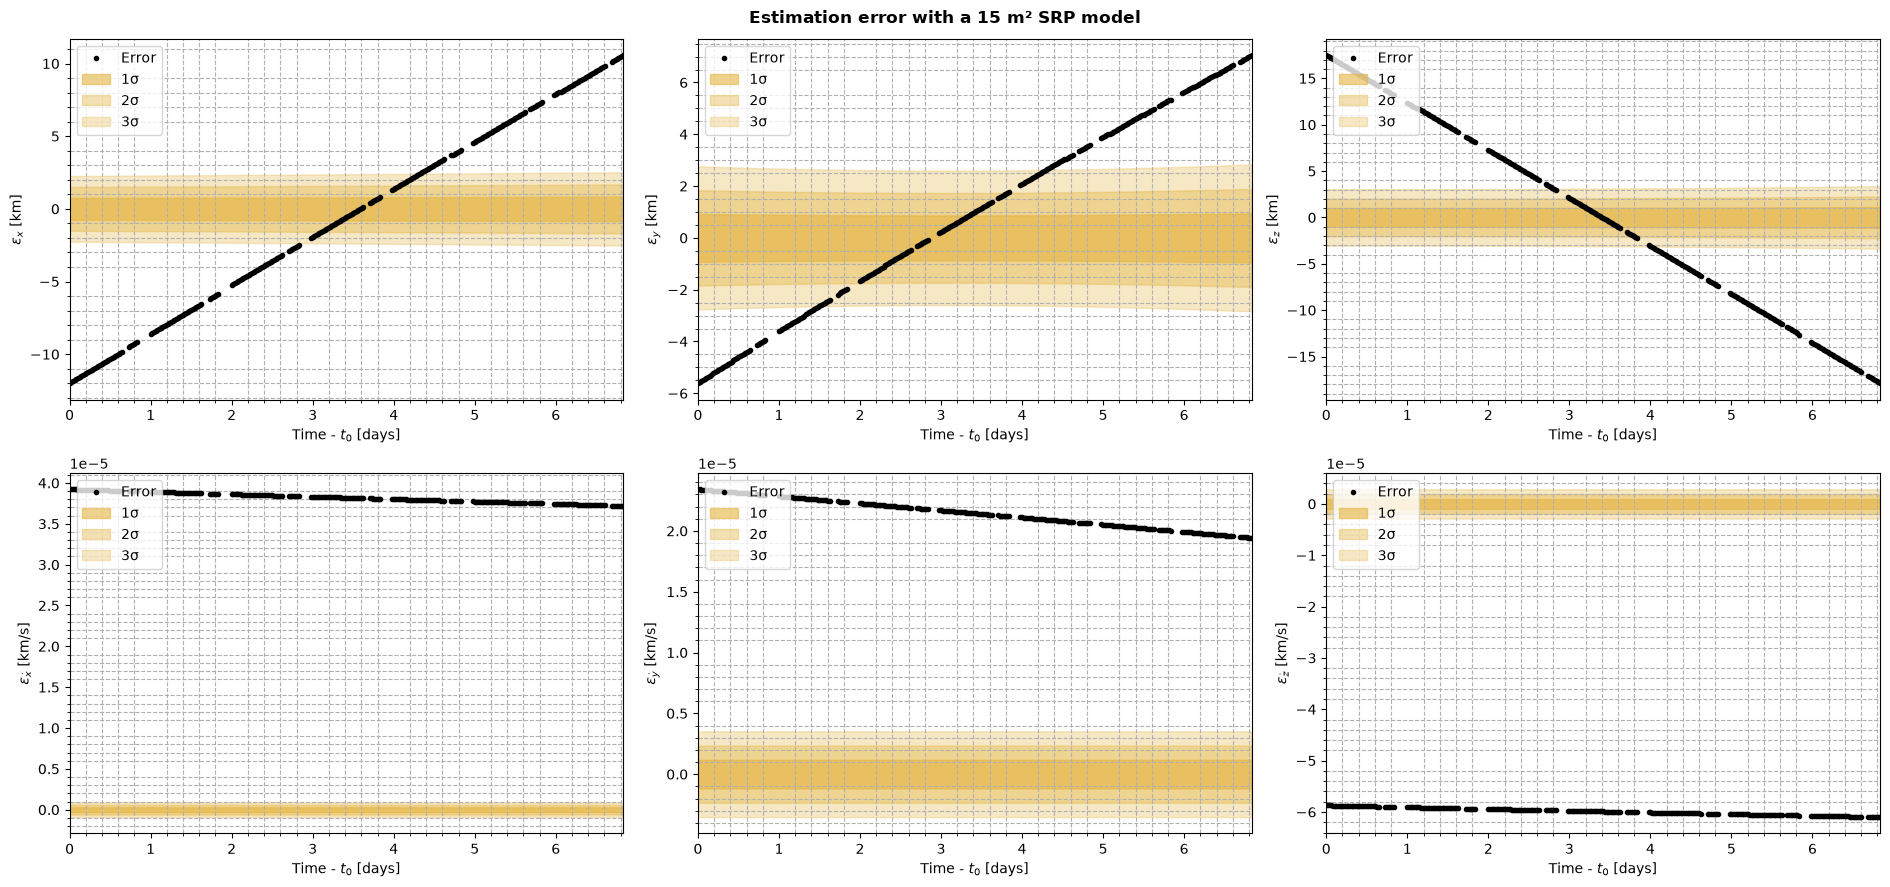

In [3]:
t_solution = scb.EpochArray(solutions["15 m², ignored"].timestamps, sys="TDB")
fig = scb.Plotting.plot_state_errors(solutions["15 m², ignored"], truth, t_solution, n_sigma=3,
                                     title="Estimation error with a 15 m² SRP model")

Compare with chapter 3, where every error stayed within 1σ: now every component leaves the 3σ band, the positions by up to ~18 km and the velocities by tens of mm/s against a 1σ of about 1 mm/s. The filter is **overconfident**: its covariance is the same as in chapter 3, but the error is an order of magnitude larger.

The residuals, the only thing available in operations, barely show it:

In [4]:
for label, solution in solutions.items():
    z = np.concatenate([np.array(r)[:, 0] / np.array(r)[:, 1] for r in solution.postfits.values()])
    print(f"{label:22s} post-fit residual RMS = {np.sqrt(np.mean(z**2)):.2f} σ")

exact model (ch. 3)    post-fit residual RMS = 0.97 σ
15 m², ignored         post-fit residual RMS = 1.06 σ


The filter absorbs the wrong acceleration into the poorly observed plane-of-sky components of the state (chapter 3, section 5), where it costs little in the residuals. An overconfident covariance with nearly normal residuals is the typical signature of mismodeled dynamics, and the reason this chapter compares against the truth. There are three standard responses.

## 2. Process noise

**Process noise** admits that the dynamics model is imperfect without saying how. Between observations the filter adds the covariance of a random acceleration, so the uncertainty grows and older data are progressively de-weighted. Only a sequential filter can do this (chapter 5): `SRIF` with `ProcessNoiseSettings`, here state noise compensation (`"SNC"`, white acceleration noise with the same σ on each axis).

The level is a tuning choice, so we scan it:

In [5]:
%%capture fit_log
scan = {}
for level in [1e-12, 1e-11, 1e-10, 1e-9]:
    snc = scb.ProcessNoiseSettings(
        type="SNC", Q_cont=scb.CovarianceMatrix([scb.ArrayWUnits(level, km / sec**2)] * 3, data_epochs[0], from_list=True)
    )
    srif = scb.SRIF(propagator=reference_propagator(orex_15, state_15), measurements=tracking,
                    settings=scb.FilterSettings(initial_covariance=P0, process_noise=snc),
                    traj_name=f"snc_{level:.0e}.bsp", traj_dir=str(out), verbose=False)
    scan[level], _, _ = srif.fit(verbose=False)

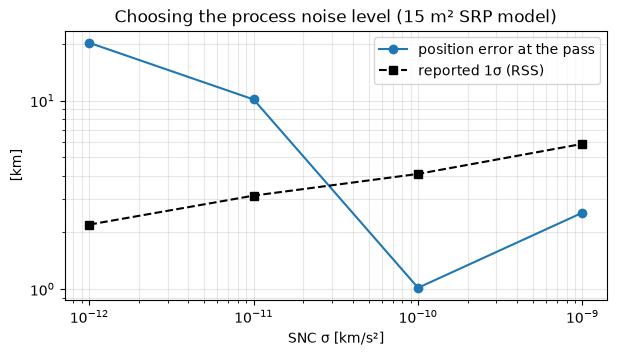

In [6]:
levels = list(scan)
error, sigma = [], []
for level, solution in scan.items():
    state_pass, P_pass = solution.propagate_state_covariance(t_pass)[0]
    error.append(np.linalg.norm(state_pass.values0.values[:3] - x_true_pass[:3]))
    sigma.append(np.sqrt(np.trace(P_pass[:3, :3])))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.loglog(levels, error, "o-", label="position error at the pass")
ax.loglog(levels, sigma, "s--", color="k", label="reported 1σ (RSS)")
ax.set(xlabel="SNC σ [km/s²]", ylabel="[km]", title="Choosing the process noise level (15 m² SRP model)")
ax.legend()
ax.grid(alpha=0.3, which="both")

Too little noise and the filter stays overconfident (error ≫ σ); too much and it discards information, so the uncertainty keeps growing. Around $10^{-10}$ km/s² the error falls inside 1σ. That level is far larger than the missing acceleration itself (~$7\times10^{-12}$ km/s²): white noise has to be strong to imitate an acceleration that is constant for a whole week.

In operations the level is chosen with the same kind of consistency check, using residual statistics and overlaps between successive solutions instead of the truth.

In [7]:
solutions["15 m², SNC 1e-10"] = scan[1e-10]

→ *Model catalogs: Process noise* (DMC, piecewise Gauss–Markov and Fourier empirical accelerations, RTN frames). The real-data chapter uses piecewise Gauss–Markov accelerations, the operational form of the same idea.

## 3. Estimating the SRP scale factor

When the *form* of the error is known, it can be modeled. Scarabaeus's SRP acceleration includes a scale factor $\eta_\text{SRP}$ (default 1) that multiplies $C_R A / m$. Adding `eta_srp` to the state as a **static, estimated** parameter lets the filter solve for it with the position and velocity. Its a-priori is 1 with a loose 1σ of 0.5, appended to the a-priori covariance:

In [8]:
%%capture fit_log
state_eta = (
    scb.StateDefinition()
    .position(orex_15, scb.ArrayWFrame(r_apriori, J2000))
    .velocity(orex_15, scb.ArrayWFrame(v_apriori, J2000))
    .param("eta_srp", orex_15, scb.ArrayWFrame(scb.ArrayWUnits([1.0], None), J2000),
           estimation="estimated", dynamics="static")
)
P0_eta = scb.CovarianceMatrix(apriori_sigmas + [scb.ArrayWUnits(0.5, None)], data_epochs[0], from_list=True)

srifb = scb.SRIFB(propagator=reference_propagator(orex_15, state_eta), measurements=tracking,
                  settings=scb.FilterSettings(initial_covariance=P0_eta),
                  traj_name="estimated.bsp", traj_dir=str(out), verbose=False)
solutions["15 m², η estimated"], _, _ = srifb.fit(verbose=False)

In [9]:
solution = solutions["15 m², η estimated"]
print(f"η_SRP = {solution.state_est[0, 6]:.4f} ± {np.sqrt(solution.covariance_est[0][6, 6]):.4f}"
      f"   (truth: 11/15 = {11 / 15:.4f})")

η_SRP = 0.7325 ± 0.0253   (truth: 11/15 = 0.7333)


/Users/andrealopez/Documents/Research/scarabaeus/src/scarabaeus/timeAndFrame/SpiceManager.py:1440: RuntimeWarning: Multiple matching JSON files found. Using most recently modified file: estimated_it2_parameters.json
  warnings.warn(


<div style="border-left:4px solid #dc2626; background:rgba(220,38,38,0.12); padding:6px 10px; border-radius:4px">
🔴 <b>FIX:</b> Reading the estimate of a run with parameters prints <code>RuntimeWarning: Multiple matching JSON files found</code> (still open in 2.0, PLAN.md): the parameter sidecar lookup matches every iteration's file by pattern and picks the most recent. The value is correct here.
</div>

The filter recovers the scale factor that corrects 15 m² to 11 m², well within its 1σ. The state now has seven components, so `state_est` and `covariance_est` grow by one row and column.

## 4. Considering the SRP scale factor

Sometimes a parameter should not be estimated: it is poorly observable from a short arc, or its value is fixed by an external calibration that the filter has no business changing. Its uncertainty is still real. A **consider** parameter keeps its a-priori value but carries its uncertainty into the covariance of the estimated states. Same state, `estimation="considered"`, with a 1σ of 0.3:

In [10]:
%%capture fit_log
state_consider = (
    scb.StateDefinition()
    .position(orex_15, scb.ArrayWFrame(r_apriori, J2000))
    .velocity(orex_15, scb.ArrayWFrame(v_apriori, J2000))
    .param("eta_srp", orex_15, scb.ArrayWFrame(scb.ArrayWUnits([1.0], None), J2000),
           estimation="considered", dynamics="static")
)
P0_consider = scb.CovarianceMatrix(apriori_sigmas + [scb.ArrayWUnits(0.3, None)], data_epochs[0], from_list=True)

srifb = scb.SRIFB(propagator=reference_propagator(orex_15, state_consider), measurements=tracking,
                  settings=scb.FilterSettings(initial_covariance=P0_consider),
                  traj_name="considered.bsp", traj_dir=str(out), verbose=False)
solutions["15 m², η considered"], _, _ = srifb.fit(verbose=False)

<div style="border-left:4px solid #dc2626; background:rgba(220,38,38,0.12); padding:6px 10px; border-radius:4px">
🔴 <b>FIX:</b> With consider parameters, <code>solution.covariance_est</code> (data noise only) is not positive semi-definite (still open in 2.0). <code>covariance_consider</code>, which <code>propagate_state_covariance</code> uses by default, is consistent with the actual errors.
</div>

The estimate is the same as when the error was ignored, since $\eta_\text{SRP}$ is not adjusted. What changes is the covariance, as the scoreboard shows.

## 5. The scoreboard

All five solutions, mapped to the start of the June 8 pass: the position error against the reported uncertainty, and the line-of-sight velocity, which is what the real Doppler data of chapter 8 will measure first.

In [11]:
names = list(solutions)
rows = []
for name in names:
    state_pass, P_pass = solutions[name].propagate_state_covariance(t_pass)[0]
    error = state_pass.values0.values[:6] - x_true_pass
    rows.append((np.linalg.norm(error[:3]), np.sqrt(np.trace(P_pass[:3, :3])),
                 abs(error[3:] @ u_pass) * 1e6, np.sqrt(u_pass @ P_pass[3:6, 3:6] @ u_pass) * 1e6))
position_error, position_sigma, los_error, los_sigma = np.array(rows).T

print(f"{'':22s} {'position [km]':^23s}   {'line-of-sight velocity [mm/s]':^30s}")
print(f"{'':22s} {'error':>7s} {'1σ':>7s} {'err/σ':>7s}   {'error':>9s} {'1σ':>9s} {'err/σ':>8s}")
for i, name in enumerate(names):
    print(f"{name:22s} {position_error[i]:7.1f} {position_sigma[i]:7.1f} {position_error[i] / position_sigma[i]:7.2f}"
          f"   {los_error[i]:9.3f} {los_sigma[i]:9.3f} {los_error[i] / los_sigma[i]:8.2f}")

                            position [km]        line-of-sight velocity [mm/s] 
                         error      1σ   err/σ       error        1σ    err/σ
exact model (ch. 3)        0.9     1.7    0.55       0.041     0.074     0.55
15 m², ignored            23.8     1.7   13.91       1.118     0.074    15.17
15 m², SNC 1e-10           1.0     4.1    0.25       0.176     0.182     0.97
15 m², η estimated         1.0     2.9    0.35       0.044     0.132     0.34
15 m², η considered       23.8    27.9    0.85       1.118     1.306     0.86


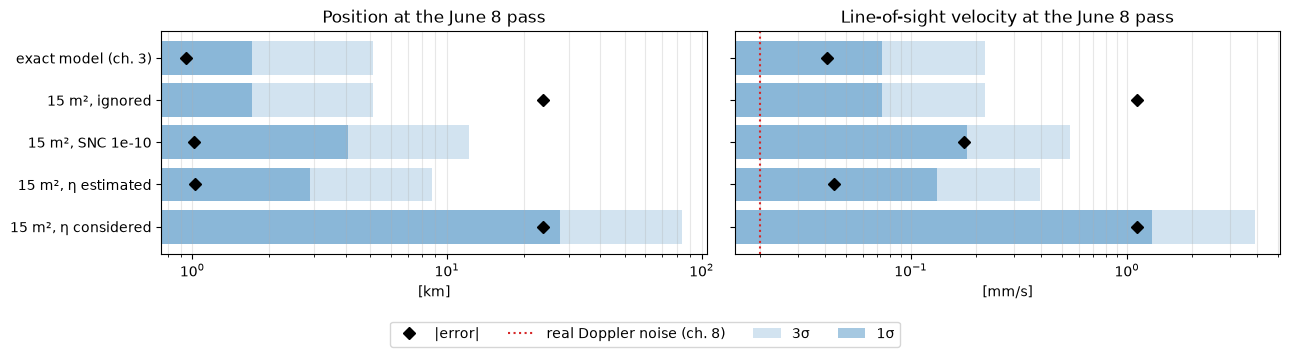

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True)
y = np.arange(len(names))[::-1]
for panel, error, sigma, unit in [(ax[0], position_error, position_sigma, "km"),
                                  (ax[1], los_error, los_sigma, "mm/s")]:
    panel.barh(y, 3 * sigma, color="tab:blue", alpha=0.2, label="3σ")
    panel.barh(y, sigma, color="tab:blue", alpha=0.4, label="1σ")
    panel.plot(error, y, "kD", label="|error|")
    panel.set(xscale="log", xlabel=f"[{unit}]")
    panel.grid(alpha=0.3, which="both", axis="x")
ax[1].axvline(0.02, color="tab:red", ls=":", label="real Doppler noise (ch. 8)")
ax[0].set(yticks=y, yticklabels=names, title="Position at the June 8 pass")
ax[1].set(title="Line-of-sight velocity at the June 8 pass")
plt.tight_layout()
fig.legend(*ax[1].get_legend_handles_labels(), loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.0))

A diamond inside its dark bar is an honest prediction; a diamond beyond the light bar is a filter that would be surprised by the real data.

- **Ignored:** the filter predicts the pass more than 10σ off. On the line of sight its velocity is off by about 1 mm/s against a claimed 0.07 mm/s: the first minutes of real Doppler (noise ~0.02 mm/s) would expose it immediately.
- **Process noise:** consistent and about as accurate as the exact model, at the cost of a looser covariance and a tuning parameter.
- **Estimated η:** the best of the three. The error is back to the chapter 3 level and the covariance grows only a little, because the data can separate the SRP scale from the initial state over a week.
- **Considered η:** the estimate is still 20+ km off, but the covariance now admits it. Considering doesn't fix the state; it makes the uncertainty honest.

**When to use which.** Unknown form of the error: process noise. Known form, observable from the data: estimate it. Known form, but poorly observable or not the filter's to adjust: consider it. Operational filters often combine all three.

## Summary

| Concept | Scarabaeus API |
|---|---|
| A different filter spacecraft | `Spacecraft(name, spice_id, mass, area, cr)` with the filter's own properties |
| Process noise | `ProcessNoiseSettings(type="SNC", Q_cont=CovarianceMatrix(...))`, `FilterSettings(process_noise=...)`, sequential filters only |
| Estimated parameter | `StateDefinition.param("eta_srp", spacecraft, value, estimation="estimated", dynamics="static")` plus its a-priori σ in `P0` |
| Consider parameter | `estimation="considered"`; `covariance_consider` |
| Prediction at any epoch | `SolutionOD.propagate_state_covariance(epochs)` (includes the consider covariance by default) |
| Error plots | `Plotting.plot_state_errors(solution, truth_trajectory, epochs, n_sigma)` |

**Try it**

- Make the error smaller: give the filter 12 m² instead of 15 m². Is ignoring it still a problem at the pass? How large is the position error compared with 1σ?
- Estimate $\eta_\text{SRP}$ with a tight a-priori σ of 0.05. What happens to the estimate, and to the scoreboard?

**Next:** 7. Data quality & planning corrupts a few observations and compares tracking plans, again on the June 8 scoreboard.